Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Testing file reading functionality...
Parsing validation data...
  Skipping duplicate Entry ID: 24130
  Skipping duplicate Entry ID: 12018
  Skipping duplicate Entry ID: 12101
  Skipping duplicate Entry ID: 12035
  Skipping duplicate Entry ID: 17061
  Skipping duplicate Entry ID: 15659
  Skipping duplicate Entry ID: 36468
  Skipping duplicate Entry ID: 5302
  Skipping duplicate Entry ID: 16460
  Skipping duplicate Entry ID: 2867
  Skipping duplicate Entry ID: 5302
  Skipping duplicate Entry ID: 32353
  Skipping duplicate Entry ID: 37049
  Skipping duplicate Entry ID: 7833
  Skipping duplicate Entry ID: 26108
  Skipping duplicate Entry ID: 17376
  Skipping duplicate Entry ID: 34441
  Skipping duplicate Entry ID: 17603
  Skipping duplicate Entry ID: 38003
  Skipping duplicate Entry ID: 3055
  Skipping duplicate Entry ID: 30676
  Skipping duplicate Entry ID: 293

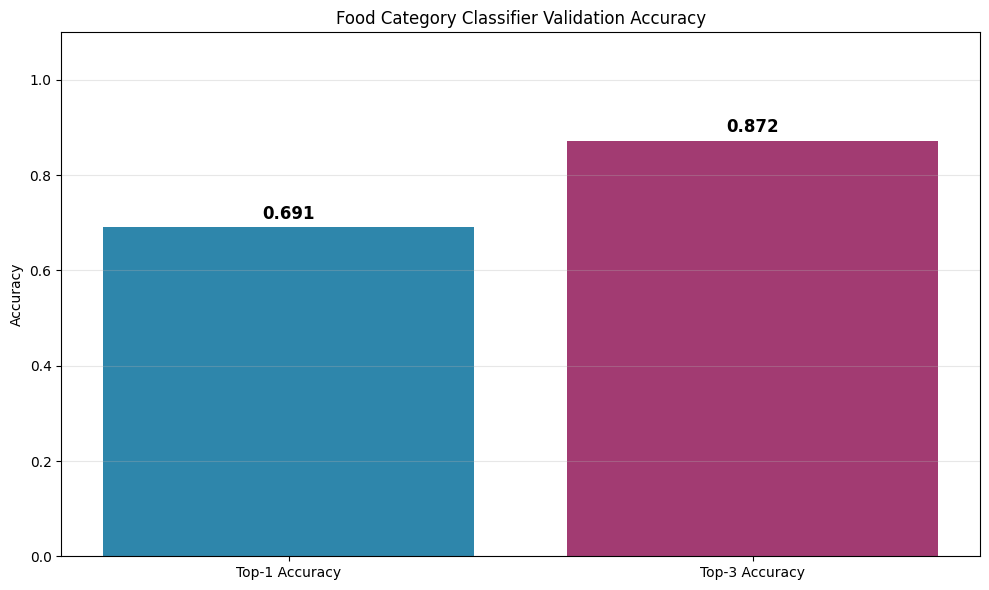

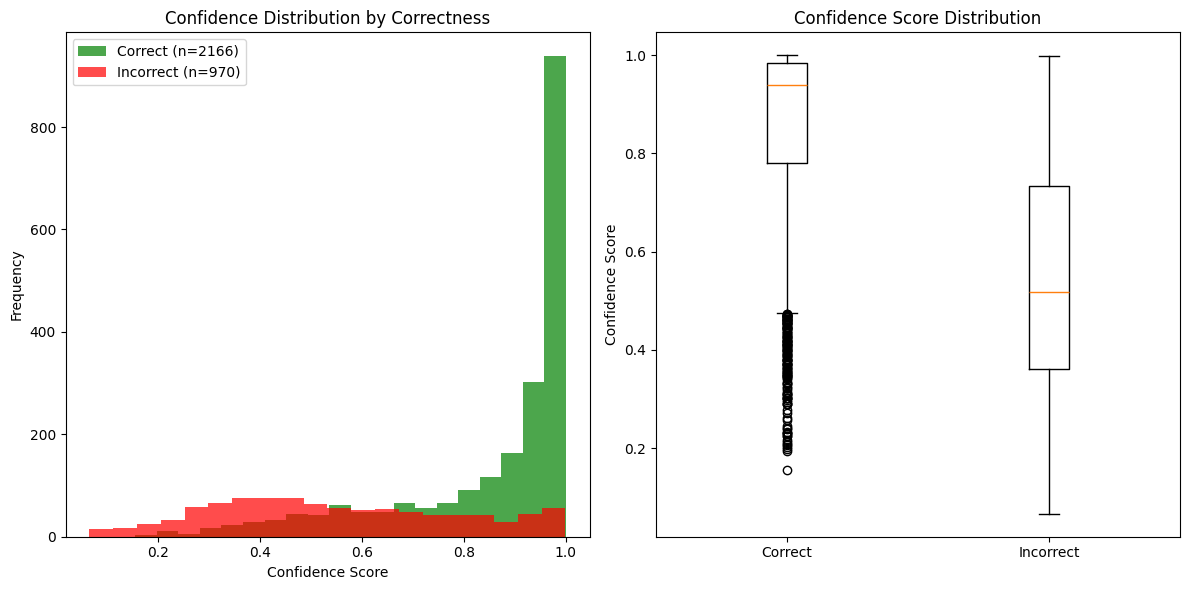

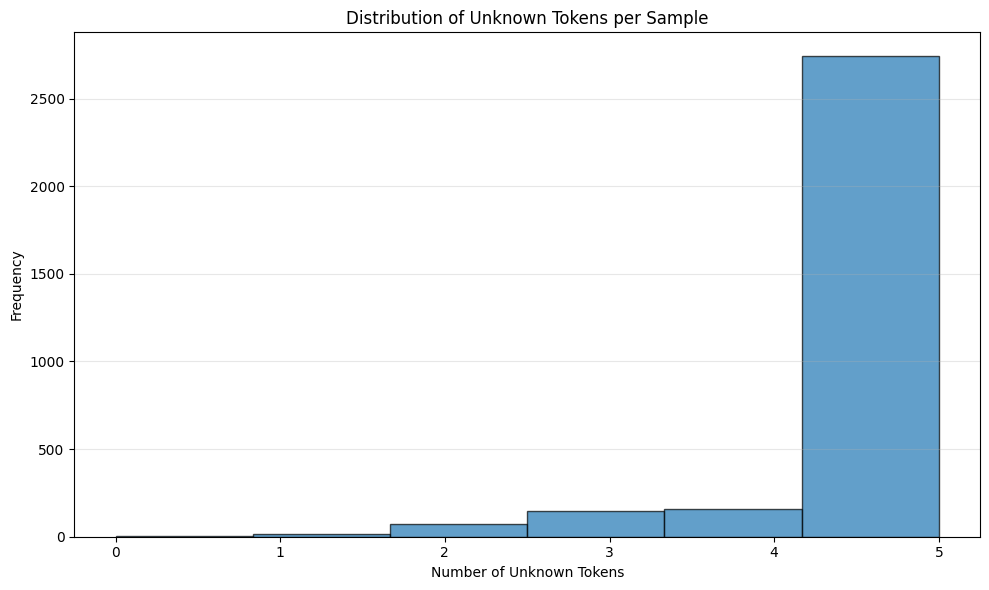

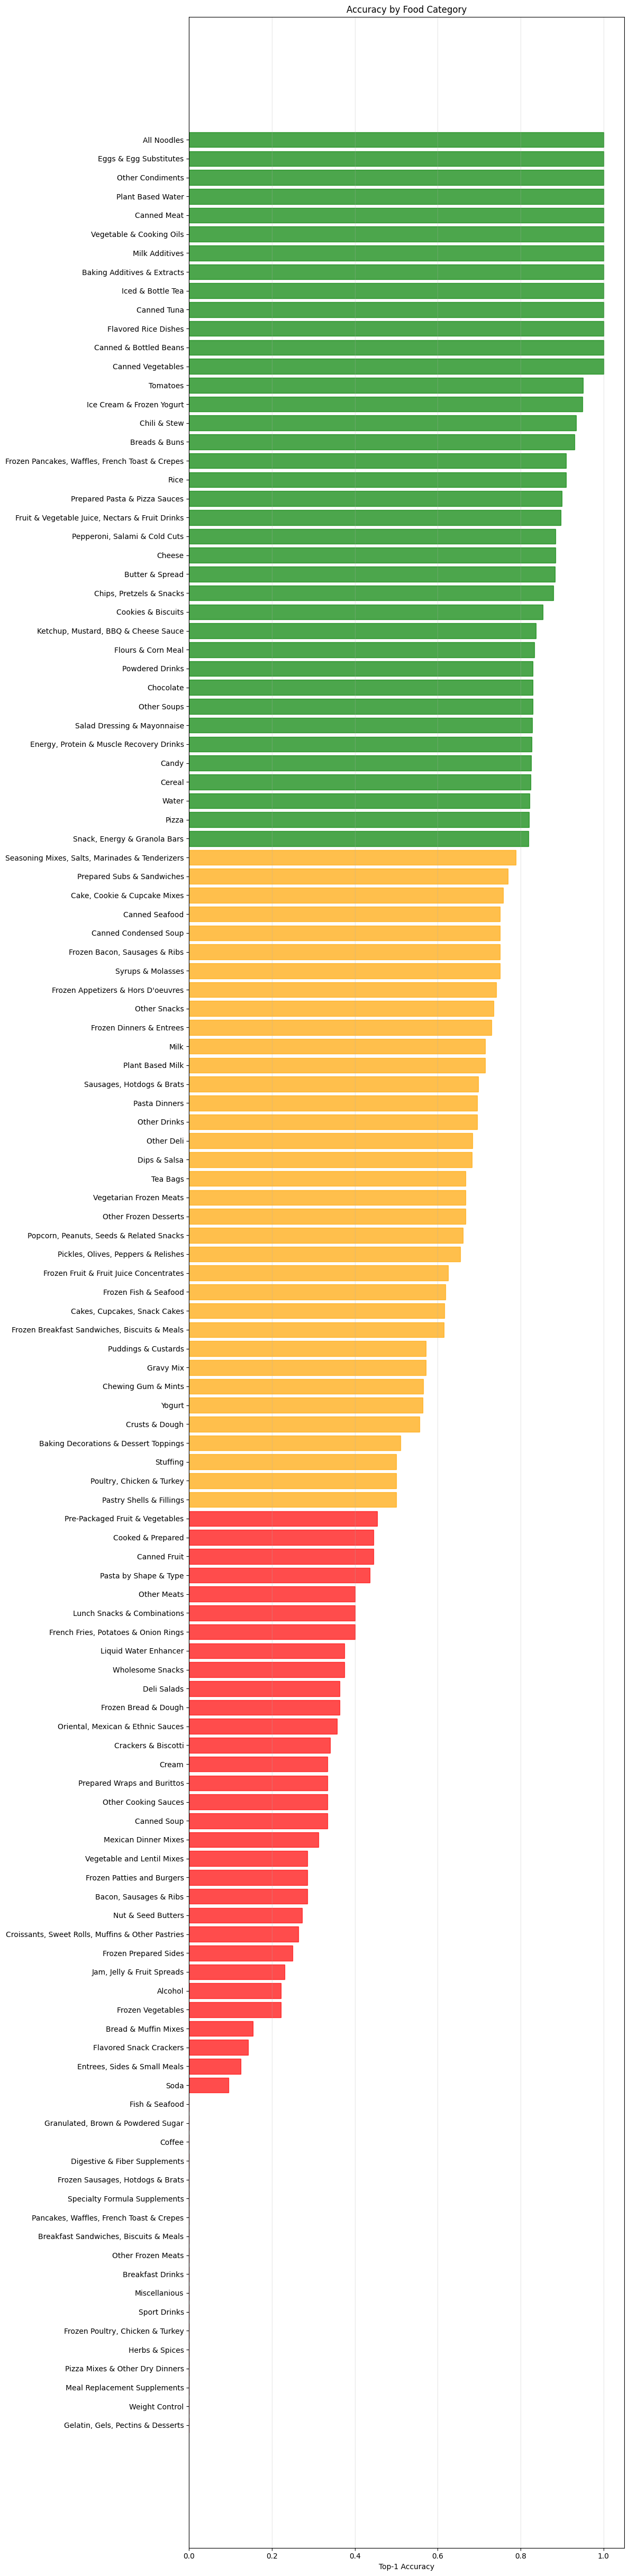

Generating report...
Saving detailed results...

VALIDATION ANALYSIS COMPLETE
Results saved to: /content/drive/MyDrive/food_classifier_validation
Top-1 Accuracy: 0.691
Top-3 Accuracy: 0.872
Total Errors: 970


In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter, defaultdict
import json
from google.colab import drive
from google.colab import files
import os
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# Mount Google Drive
drive.mount('/content/drive')

class FoodClassifierAnalyzer:
    def __init__(self):
        self.results = []
        self.validation_data = []

    def parse_validation_output(self, text_data):
      entries = []
      seen_entry_ids = set()  # Track seen entry IDs
      duplicate_count = 0     # Count duplicates

      # Split by entry patterns
      entry_pattern = r'📝 Random sample loaded:'
      raw_entries = re.split(entry_pattern, text_data)[1:]  # Skip first empty split
      for raw_entry in raw_entries:
            try:
                entry_data = {}

                # Extract basic info
                entry_id_match = re.search(r'Entry ID: (\d+)', raw_entry)
                product_match = re.search(r'Product: ([^\n]+)', raw_entry)
                brand_match = re.search(r'Brand: ([^\n]+)', raw_entry)
                category_match = re.search(r'Category: ([^\n]+)', raw_entry)
                brand_name_match = re.search(r'Brand Name: ([^\n]+)', raw_entry)

                if not all([entry_id_match, product_match, brand_match, category_match]):
                    continue

                entry_id = int(entry_id_match.group(1))

                # Skip if duplicate entry ID
                if entry_id in seen_entry_ids:
                    duplicate_count += 1
                    print(f"  Skipping duplicate Entry ID: {entry_id}")
                    continue

                # Add to seen set
                seen_entry_ids.add(entry_id)
                entry_data['entry_id'] = entry_id
                entry_data['product'] = product_match.group(1)
                entry_data['brand'] = brand_match.group(1)
                entry_data['ground_truth_category'] = category_match.group(1)
                entry_data['brand_name'] = brand_name_match.group(1) if brand_name_match else ''

                # Extract ingredients
                ingredients_match = re.search(r"Original: '([^']+)'", raw_entry)
                entry_data['ingredients'] = ingredients_match.group(1) if ingredients_match else ''

                # Extract unknown tokens
                unknown_tokens_match = re.search(r'⚠️ Unknown tokens: \[([^\]]+)\]', raw_entry)
                if unknown_tokens_match:
                    unknown_tokens_str = unknown_tokens_match.group(1)
                    entry_data['unknown_tokens'] = [t.strip('"') for t in unknown_tokens_str.split(', ')]
                    entry_data['num_unknown_tokens'] = len(entry_data['unknown_tokens'])
                else:
                    entry_data['unknown_tokens'] = []
                    entry_data['num_unknown_tokens'] = 0

                # Extract top 3 predictions
                predictions = []
                pred_pattern = r'(\d+)\.\s+([^:]+):\s+([\d.]+)'
                for match in re.finditer(pred_pattern, raw_entry):
                    rank, category, confidence = match.groups()
                    predictions.append({
                        'rank': int(rank),
                        'category': category.strip(),
                        'confidence': float(confidence)
                    })

                if predictions:
                    entry_data['predictions'] = predictions
                    entry_data['top1_prediction'] = predictions[0]['category']
                    entry_data['top1_confidence'] = predictions[0]['confidence']

                    # Check accuracy
                    entry_data['top1_correct'] = (predictions[0]['category'] == entry_data['ground_truth_category'])
                    entry_data['top3_correct'] = any(p['category'] == entry_data['ground_truth_category'] for p in predictions)

                    entries.append(entry_data)

            except Exception as e:
                print(f"Error parsing entry: {e}")
                continue
      print(f"Parsing complete: {len(entries)} unique entries processed")
      if duplicate_count > 0:
        print(f"  {duplicate_count} duplicate entries were skipped")
      return entries

    def calculate_accuracy_metrics(self, entries):
        """Calculate validation accuracy metrics"""
        if not entries:
            return {}

        total_samples = len(entries)
        top1_correct = sum(1 for e in entries if e.get('top1_correct', False))
        top3_correct = sum(1 for e in entries if e.get('top3_correct', False))

        metrics = {
            'total_samples': total_samples,
            'top1_accuracy': top1_correct / total_samples,
            'top3_accuracy': top3_correct / total_samples,
            'top1_correct_count': top1_correct,
            'top3_correct_count': top3_correct
        }

        return metrics

    def analyze_error_patterns(self, entries):
        """Analyze misclassification patterns"""
        errors = []
        category_confusion = defaultdict(lambda: defaultdict(int))

        for entry in entries:
            if not entry.get('top1_correct', True):  # Top-1 error
                error_data = {
                    'entry_id': entry['entry_id'],
                    'product': entry['product'],
                    'ground_truth': entry['ground_truth_category'],
                    'predicted': entry['top1_prediction'],
                    'confidence': entry['top1_confidence'],
                    'num_unknown_tokens': entry['num_unknown_tokens'],
                    'unknown_tokens': entry['unknown_tokens']
                }
                errors.append(error_data)
                category_confusion[entry['ground_truth_category']][entry['top1_prediction']] += 1

        return errors, dict(category_confusion)

    def analyze_confidence_distribution(self, entries):
        """Analyze confidence score distributions"""
        correct_confidences = []
        incorrect_confidences = []

        for entry in entries:
            confidence = entry.get('top1_confidence', 0)
            if entry.get('top1_correct', False):
                correct_confidences.append(confidence)
            else:
                incorrect_confidences.append(confidence)

        return {
            'correct_confidences': correct_confidences,
            'incorrect_confidences': incorrect_confidences,
            'avg_correct_confidence': np.mean(correct_confidences) if correct_confidences else 0,
            'avg_incorrect_confidence': np.mean(incorrect_confidences) if incorrect_confidences else 0
        }

    def create_visualizations(self, entries, metrics, confidence_analysis, save_dir):
        """Create validation result visualizations"""

        # 1. Accuracy Bar Chart
        plt.figure(figsize=(10, 6))
        accuracies = [metrics['top1_accuracy'], metrics['top3_accuracy']]
        labels = ['Top-1 Accuracy', 'Top-3 Accuracy']
        bars = plt.bar(labels, accuracies, color=['#2E86AB', '#A23B72'])

        # Add value labels on bars
        for bar, acc in zip(bars, accuracies):
            plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                    f'{acc:.3f}', ha='center', va='bottom', fontsize=12, fontweight='bold')

        plt.ylim(0, 1.1)
        plt.ylabel('Accuracy')
        plt.title('Food Category Classifier Validation Accuracy')
        plt.grid(axis='y', alpha=0.3)
        plt.tight_layout()
        plt.savefig(f'{save_dir}/accuracy_comparison.png', dpi=300, bbox_inches='tight')
        plt.show()

        # 2. Confidence Distribution
        plt.figure(figsize=(12, 6))
        correct_conf = confidence_analysis['correct_confidences']
        incorrect_conf = confidence_analysis['incorrect_confidences']

        plt.subplot(1, 2, 1)
        plt.hist(correct_conf, bins=20, alpha=0.7, color='green', label=f'Correct (n={len(correct_conf)})')
        plt.hist(incorrect_conf, bins=20, alpha=0.7, color='red', label=f'Incorrect (n={len(incorrect_conf)})')
        plt.xlabel('Confidence Score')
        plt.ylabel('Frequency')
        plt.title('Confidence Distribution by Correctness')
        plt.legend()

        plt.subplot(1, 2, 2)
        box_data = [correct_conf, incorrect_conf]
        box_labels = ['Correct', 'Incorrect']
        plt.boxplot(box_data, labels=box_labels)
        plt.ylabel('Confidence Score')
        plt.title('Confidence Score Distribution')

        plt.tight_layout()
        plt.savefig(f'{save_dir}/confidence_analysis.png', dpi=300, bbox_inches='tight')
        plt.show()

        # 3. Unknown Tokens Analysis
        plt.figure(figsize=(10, 6))
        unknown_counts = [entry['num_unknown_tokens'] for entry in entries]
        plt.hist(unknown_counts, bins=max(unknown_counts) + 1, alpha=0.7, edgecolor='black')
        plt.xlabel('Number of Unknown Tokens')
        plt.ylabel('Frequency')
        plt.title('Distribution of Unknown Tokens per Sample')
        plt.grid(axis='y', alpha=0.3)
        plt.tight_layout()
        plt.savefig(f'{save_dir}/unknown_tokens_distribution.png', dpi=300, bbox_inches='tight')
        plt.show()

        # 4. Category Performance Analysis
        category_performance = defaultdict(lambda: {'correct': 0, 'total': 0})
        for entry in entries:
            gt_cat = entry['ground_truth_category']
            category_performance[gt_cat]['total'] += 1
            if entry.get('top1_correct', False):
                category_performance[gt_cat]['correct'] += 1

        # Calculate accuracy per category
        cat_accuracies = {}
        for cat, perf in category_performance.items():
            if perf['total'] > 0:
                cat_accuracies[cat] = perf['correct'] / perf['total']

        if cat_accuracies:
            # Sort by accuracy
            sorted_cats = sorted(cat_accuracies.items(), key=lambda x: x[1])

            plt.figure(figsize=(12, max(8, len(sorted_cats) * 0.4)))
            categories, accuracies = zip(*sorted_cats)
            bars = plt.barh(categories, accuracies)

            # Color code bars
            colors = ['red' if acc < 0.5 else 'orange' if acc < 0.8 else 'green' for acc in accuracies]
            for bar, color in zip(bars, colors):
                bar.set_color(color)
                bar.set_alpha(0.7)

            plt.xlabel('Top-1 Accuracy')
            plt.title('Accuracy by Food Category')
            plt.grid(axis='x', alpha=0.3)
            plt.tight_layout()
            plt.savefig(f'{save_dir}/category_performance.png', dpi=300, bbox_inches='tight')
            plt.show()

    def generate_report(self, entries, metrics, errors, confidence_analysis, save_dir):
        """Generate comprehensive validation report"""

        report = f"""
# Food Category Classifier Validation Report
Generated: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}

## Summary Metrics
- **Total Test Samples**: {metrics['total_samples']}
- **Top-1 Accuracy**: {metrics['top1_accuracy']:.3f} ({metrics['top1_correct_count']}/{metrics['total_samples']})
- **Top-3 Accuracy**: {metrics['top3_accuracy']:.3f} ({metrics['top3_correct_count']}/{metrics['total_samples']})

## Confidence Analysis
- **Average Confidence (Correct)**: {confidence_analysis['avg_correct_confidence']:.3f}
- **Average Confidence (Incorrect)**: {confidence_analysis['avg_incorrect_confidence']:.3f}

## Error Analysis
- **Total Misclassifications**: {len(errors)}
- **Error Rate**: {len(errors)/metrics['total_samples']:.3f}

### Top Misclassified Categories
"""

        # Add error details
        if errors:
            error_df = pd.DataFrame(errors)
            gt_error_counts = error_df['ground_truth'].value_counts().head(10)

            report += "\n#### Ground Truth Categories with Most Errors:\n"
            for cat, count in gt_error_counts.items():
                report += f"- {cat}: {count} errors\n"

        # Unknown tokens analysis
        all_unknown = []
        for entry in entries:
            all_unknown.extend(entry.get('unknown_tokens', []))

        if all_unknown:
            unknown_counts = Counter(all_unknown)
            report += f"\n### Most Common Unknown Tokens\n"
            for token, count in unknown_counts.most_common(20):
                report += f"- {token}: {count} occurrences\n"

        # Save report
        with open(f'{save_dir}/validation_report.md', 'w') as f:
            f.write(report)

        return report

    def save_detailed_results(self, entries, errors, save_dir):
        """Save detailed results to CSV files"""

        # Save all results
        if entries:
            df_results = pd.DataFrame(entries)
            df_results.to_csv(f'{save_dir}/validation_results.csv', index=False)

        # Save errors
        if errors:
            df_errors = pd.DataFrame(errors)
            df_errors.to_csv(f'{save_dir}/validation_errors.csv', index=False)

    def run_full_analysis(self, validation_text, output_dir='/content/drive/MyDrive/food_classifier_validation'):
        """Run complete validation analysis"""

        # Create output directory
        os.makedirs(output_dir, exist_ok=True)

        print("Parsing validation data...")
        entries = self.parse_validation_output(validation_text)
        print(f"Parsed {len(entries)} validation entries")

        if not entries:
            print("No entries found to analyze!")
            return

        print("Calculating metrics...")
        metrics = self.calculate_accuracy_metrics(entries)

        print("Analyzing error patterns...")
        errors, confusion_matrix = self.analyze_error_patterns(entries)

        print("Analyzing confidence distributions...")
        confidence_analysis = self.analyze_confidence_distribution(entries)

        print("Creating visualizations...")
        self.create_visualizations(entries, metrics, confidence_analysis, output_dir)

        print("Generating report...")
        report = self.generate_report(entries, metrics, errors, confidence_analysis, output_dir)

        print("Saving detailed results...")
        self.save_detailed_results(entries, errors, output_dir)

        # Print summary
        print("\n" + "="*50)
        print("VALIDATION ANALYSIS COMPLETE")
        print("="*50)
        print(f"Results saved to: {output_dir}")
        print(f"Top-1 Accuracy: {metrics['top1_accuracy']:.3f}")
        print(f"Top-3 Accuracy: {metrics['top3_accuracy']:.3f}")
        print(f"Total Errors: {len(errors)}")

        return {
            'entries': entries,
            'metrics': metrics,
            'errors': errors,
            'confidence_analysis': confidence_analysis,
            'report': report
        }


# Quick test with sample data (for demonstration)
def run_sample_test():
    # Create a temporary sample file
    sample_data = '''📝 Random sample loaded:
   Entry ID: 28135
   Product: ORGANIC TORTILLA CHIPS
   Brand: Kohl Corporation
   Category: Chips, Pretzels & Snacks
   Ingredients: 253 characters
   Brand Name: GREEN WAY
🔍 FoodClassifier Debug:
  Original: 'ORGANIC CORN FLOUR, ORGANIC VEGETABLE OIL (ORGANIC SUNFLOWER AND/OR ORGANIC SAFFLOWER OIL), ORGANIC SWEET POTATO, ORGANIC CANE SUGAR, ORGANIC SUCANAT WITH HONEY (ORGANIC DRIED CANE SYRUP, ORGANIC HONEY, ORGANIC CANE MOLASSES), SEA SALT, ORGANIC ANNATTO.'
  Preprocessed: 'organic corn flour, organic vegetable oil (organic sunflower and/or organic safflower oil), organic sweet potato, organic cane sugar, organic sucanat with honey (organic dried cane syrup, organic honey, organic cane molasses), sea salt, organic annatto.'
  Tokens (first 10): ["[CLS]", "organic", "corn", "flour", ",", "organic", "vegetable", "oil", "(", "organic"]
  Input IDs (first 10): [101, 7554, 9781, 13724, 1010, 7554, 15415, 3514, 1006, 7554]
  Attention mask sum: 50/256
  ⚠️ Unknown tokens: ["sunflower", "safflower", "sucanat", "molasses", "annatto"]
  Raw logits (first 5): [-8.0390625, -5.30078125, -2.90234375, -7.9765625, -7.890625]
  Top 3 predictions:
    1. Chips, Pretzels & Snacks: 0.994
    2. Other Snacks: 0.003
    3. Snacks: 0.001'''

    # Save to temporary file
    with open('sample_validation.txt', 'w') as f:
        f.write(sample_data)

    # Test file reading
    print("Testing file reading functionality...")
    analyzer = FoodClassifierAnalyzer()
    path1='/content/drive/MyDrive/Food additives RAG+LLM/2.10.1/2.10.1.txt'
    with open(path1, 'r') as file:
        content2 = file.read()
    results = analyzer.run_full_analysis(validation_text=content2)

    return results

# Uncomment the line below to run the sample test
test_results = run_sample_test()